In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Load your dataset
df = pd.read_csv("StudentPerformanceFactors.csv")

In [ ]:
# Set your target column
target = "Exam_Score"

In [ ]:
# Encode categorical columns
df = pd.get_dummies(df, drop_first=True)

In [ ]:
# Split features/target
X = df.drop(columns=[target]).values
y = df[target].values.reshape(-1, 1)

In [ ]:
# Train/Val/Test split (60/20/20)
# 60% train, 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

# Split remaining 40% into 20% val and 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

In [ ]:
# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
# Convert to tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

train_ds = TensorDataset(X_train_t, y_train_t)
val_ds = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 1),

        )

    def forward(self, x):
        return self.model(x)

model = NeuralNetwork(X_train.shape[1])
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [ ]:
# Training loop
epochs = 1000

# Lists to store losses for plotting
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    current_train_loss = 0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()
        current_train_loss += loss.item()

    model.eval()
    current_val_loss = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            preds = model(xb)
            loss = criterion(preds, yb)
            current_val_loss += loss.item()

    # Store losses
    train_losses.append(current_train_loss)
    val_losses.append(current_val_loss)

    if epoch % 20 == 0:
        print(f"Epoch {epoch}, Train Loss: {current_train_loss:.4f}, Val Loss: {current_val_loss:.4f}")
torch.save(model.state_dict(), "student_linear_regression.pth")
print("Model saved!")

Epoch 0, Train Loss: 554401.1724, Val Loss: 183934.9155
Epoch 20, Train Loss: 239382.7301, Val Loss: 78699.4010
Epoch 40, Train Loss: 71833.2740, Val Loss: 23141.8218
Epoch 60, Train Loss: 8530.0423, Val Loss: 2539.0706
Epoch 80, Train Loss: 606.6093, Val Loss: 122.4192
Epoch 100, Train Loss: 581.9772, Val Loss: 119.2323
Epoch 120, Train Loss: 584.7040, Val Loss: 119.1409
Epoch 140, Train Loss: 585.3841, Val Loss: 121.3201
Epoch 160, Train Loss: 582.6311, Val Loss: 119.9438
Epoch 180, Train Loss: 585.5261, Val Loss: 118.2196
Epoch 200, Train Loss: 587.8341, Val Loss: 117.1652
Epoch 220, Train Loss: 585.2117, Val Loss: 116.6654
Epoch 240, Train Loss: 584.4182, Val Loss: 119.0152
Epoch 260, Train Loss: 584.0857, Val Loss: 119.0078
Epoch 280, Train Loss: 587.6913, Val Loss: 119.0486
Epoch 300, Train Loss: 585.4995, Val Loss: 118.1136
Epoch 320, Train Loss: 585.8651, Val Loss: 122.1081
Epoch 340, Train Loss: 582.2327, Val Loss: 119.1771
Epoch 360, Train Loss: 581.6661, Val Loss: 119.3822
E

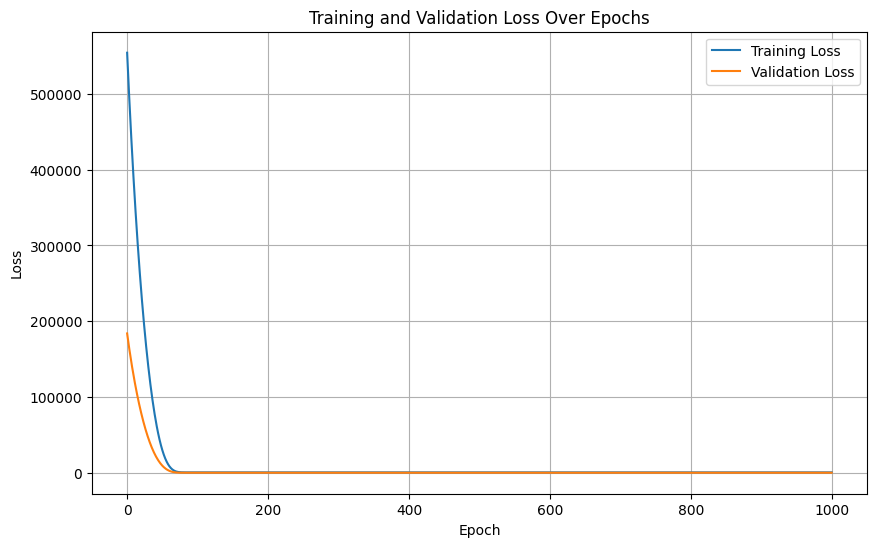

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
#plt.ylim(0, 10000) # Set y-axis limit
plt.show()

In [ ]:
# Final evaluation on test set
model.eval()
with torch.no_grad():
    y_pred = model(X_test_t).numpy()

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R²:", r2)

Test MSE: 3.9475183486938477
Test RMSE: 1.986836266201583
Test R²: 0.7250385284423828


In [ ]:
import os
os.listdir('/content')

['.config',
 'StudentPerformanceFactors.csv',
 'student_linear_regression.pth',
 'sample_data']

In [ ]:
from google.colab import files
files.download("student_linear_regression.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>